In [1]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/RNN/Experiment_1

/Users/cl1704/PycharmProjects/embedding_dimension/RNN/Experiment_1


In [4]:

from TwoAFCTask import generate_trials
from scipy.stats import ortho_group

#from Experiment_5.SiegelMillerTask import generate_trials
import networkx as nx
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import gridspec
import seaborn as sns
from net import *
import os
import statsmodels.api as sm
import scipy.optimize as opt
from scipy.stats import special_ortho_group
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
import math
#from psychometrics import *
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
import networkx as nx
from sklearn.cluster import KMeans

plt.rcParams["axes.grid"] = False
from sklearn.manifold import TSNE

matplotlib.rcParams['axes.linewidth'] = .5


def compute_var(variance, n):
    return np.sum(variance[n:])


def compute_p(k, null_k):
    return np.sum(null_k < k) / len(null_k)


df_list = []
for filename in os.listdir('Results_1'):
    f = os.path.join('Results_1', filename)
    if os.path.isfile(f):
        df_list.append(pd.read_pickle(f))
original_df = pd.concat(df_list,ignore_index=True) 
#original_df = original_df[original_df.mse_z<.035]

df = original_df.copy()

# Restrict to networks with dim and compute variance above dim
dim = 2
df = df[df.dim == dim]
#df = df[df.k >= dim]
df['var'] = df.variance.apply(lambda x: compute_var(x, dim))
df['k_inertia'] = df.inertia.apply(lambda x: x[dim - 1])
df.sort_values('var', ascending=True)




,model_id,w_rec,w_in,w_out,bias,mse_z,weight_decay,threshold,sigma_rec,lambda_std,...,lvar,dim,k,p_value,inertia,activity_std,null_inertia,variance,var,k_inertia
0,25OfcHVL,"[[0.010596836, -0.0093914205, -0.010708517, -0...","[[-0.039231226, 0.043990567], [0.053146042, -0...","[[0.015396387, 0.13326709, 0.13448171, 0.13376...","[0.06904768, 0.070694946, 0.07214994, 0.071560...",0.022596,0.01,0.025,0.0,1.0,...,2.0,2,2,0.0,"[0.8742351453329119, 7.765624270078808e-06, 3....",0.016789,"[[0.9713026308259423, 0.9987345822330881, 0.99...","[0.87789863, 0.122096434, 3.8229455e-06, 4.296...",0.000005,0.000008


0.09447605977500957


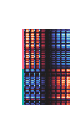

In [63]:
## CLUSTERED RESPONSE MATRIX        
#_,k = compute_k(responses,5,25,.05)

## RESPONSE MATRIX
model_data = original_df[original_df.model_id == '25OfcHVL']
net = Net(n=100,input_size = 2,dale=False)
net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'].item())
net.recurrent_layer.bias.data = torch.tensor(model_data['bias'].item())
net.input_layer.weight.data = torch.tensor(model_data['w_in'].item())
net.output_layer.weight.data = torch.tensor(model_data['w_out'].item())
net.sigma_rec = 0.
net.sigma_in = 0.1


u, z, mask, conditions  = generate_trials(
                            n_trials=50)
x = net(u).detach().cpu().numpy()

#activity_std = torch.std(torch.mean(x, dim=[0, 1])).detach().cpu().numpy() / torch.mean(torch.mean(x, dim=[0, 1])).detach().cpu().numpy()
# activity_std = torch.std(torch.mean(x, dim=[0, 1])).detach().cpu().numpy() / torch.mean(torch.mean(x, dim=[0, 1])).detach().cpu().numpy()
# 
rows = []
for k in range(u.shape[0]):
    rows.append({'trial': k,
                 'motion': conditions[k]['motion_coh'],
                 'response': x[k, :, :]})
df = pd.DataFrame(rows)
df = df.groupby(['motion']).response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()

#df = df.groupby('motion').response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()
responses = np.stack(df.response.values)
responses = responses.reshape(-1, responses.shape[2]).T

#responses = responses[np.mean(responses, axis=1) >.025, :]


responses = (responses - np.mean(responses, axis=1, keepdims=True)) / np.std(responses, axis=1, keepdims=True)
responses = responses[~np.isnan(responses).any(axis=1)]


#rot = ortho_group.rvs(responses.shape[0])
a0 = np.zeros((100,100))
a1 = .4*np.random.rand(100,100)
skew_0 = (a0 - a0.T) / 2
skew_1 = (a1 - a1.T) / 2

skew = skew_0 + 0.4*(skew_1-skew_0)
eye = np.eye(100)
o = (eye - skew) @ np.linalg.inv(eye + skew)
#responses =  responses @ torch.tensor(o).float()
    
responses = o @ responses
        
k = model_data.k.values[0]
##k = 2
import matplotlib
#clustering = KMeans(n_clusters=k, n_init=20).fit(responses)
total_variance = np.sum((responses.T - np.mean(responses.T, axis=0, keepdims=True)) ** 2)
print(clustering.inertia_/total_variance)
labels = clustering.labels_
sort = np.argsort(labels)
sorted_responses = responses[sort, :]
sns.husl_palette(s=.4)
network_pal = sns.husl_palette(pd.Series(np.sort(labels)).unique().size, s=1)
lut = dict(zip(pd.Series(np.sort(labels)).unique(), network_pal))
row_colors = pd.Series(np.sort(labels)).map(lut)
g = sns.clustermap(pd.DataFrame((sorted_responses)), row_cluster=False, col_cluster=False, row_colors=row_colors,
                   figsize=(.9, 1.25), xticklabels=False, yticklabels=False,center=0,vmin=-2.5,vmax=2.5,cbar_pos = None)
ax = g.ax_heatmap

g.savefig('/Users/cl1704/PycharmProjects/embedding_dimension/RNN/Figures/response_matrix.jpg',
          format='jpeg',
          dpi=450,
          bbox_inches='tight'
          )

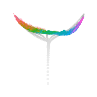

In [64]:
fig = plt.figure(figsize=(1,1))
gs = gridspec.GridSpec(1,1)
u, z, mask, conditions  = generate_trials(
                            n_trials=25)


ax=fig.add_subplot(gs[0,0])
model_data = original_df[original_df.model_id == "25OfcHVL"]
net = Net(n=100, input_size=2, dale=False)
net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'].item())
net.recurrent_layer.bias.data = torch.tensor(model_data['bias'].item())
net.input_layer.weight.data = torch.tensor(model_data['w_in'].item())
net.output_layer.weight.data = torch.tensor(model_data['w_out'].item())
#net.activation = torch.nn.Softplus(beta=model_data['beta'].item())
net.sigma_in = 0.1
net.sigma_rec = 0
x = net.forward(u).detach().numpy()
#x = (x - np.mean(x, axis=(0, 1), keepdims=True)) / np.std(x, axis=(0, 1), keepdims=True)
#x = net(u)
n_components = 2
pca = PCA()
pca.fit(x.reshape(-1, x.shape[2]))
x_proj = pca.transform(x.reshape(-1, x.shape[2])).reshape(x.shape[0], x.shape[1], x.shape[2])

rows = []
for k in range(u.shape[0]):
    for t in range(u.shape[1]):
        rows.append({'trial': k,
                     'motion': conditions[k]['motion_coh'],
                     'side': np.sign(conditions[k]['motion_coh']),
                     't': t,
                     'z_1': x_proj[k, t, 0],
                     'z_2': -x_proj[k, t, 1], })

new_df = pd.DataFrame(rows)
new_df_mean = new_df.groupby(['motion', 't']).mean().reset_index()
#sns.blend_palette(["lightgray", "gray"]
palette = sns.husl_palette(n_colors = 9,s=1)
# sns.scatterplot(data=new_df,x='z_1',y='z_2',hue='t',ax=ax,legend=False,s=1,alpha=1,palette = sns.blend_palette(["lightgray", "gray"], as_cmap=True),edgecolor=None)
sns.scatterplot(data=new_df_mean,x='z_1',y='z_2',hue='t',ax=ax,legend=False,s=.75,alpha=1,palette = sns.light_palette("gray",as_cmap=True),edgecolor=None)
sns.scatterplot(data=new_df_mean[new_df_mean.t>70],x='z_1',y='z_2',hue='motion',ax=ax,legend=False,s=2,alpha=1,palette = palette,edgecolor=None)
sns.scatterplot(data=new_df[new_df.t>70],x='z_1',y='z_2',hue='motion',ax=ax,legend=False,s=.25,alpha=.5,palette = palette,edgecolor=None)

# sns.scatterplot(data=new_df_mean[new_df_mean.t==74], x='z_1', y='z_2', ax=ax, legend=False, s=2, alpha=1, hue='motion',
#                 palette=palette)
# 
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_xlabel("PC 1", fontsize=7)
ax.set_ylabel("PC 2", fontsize=7)

variance = np.sum(pca.explained_variance_ratio_[2:])    
#ax.set_title(r'$\sum_{i\geq 2}\lambda_i = $'+str(np.round(variance,4)),fontsize=8)
ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=7, left=True)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
fig.savefig('/Users/cl1704/PycharmProjects/embedding_dimension/RNN/Figures/2afc_manifolds.jpg',
    format='jpeg',
    dpi=450,
            bbox_inches='tight'
)

0.2328180379651005


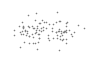

In [65]:
# Trial data for simulations
u, z, mask, conditions  = generate_trials(
                                    n_trials=100)



fig = plt.figure(figsize=(1,1))
gs = gridspec.GridSpec(1,1)


#bins = np.linspace(-3,-.75,9)

# 
# df['bin'] = pd.cut(df['var'],bins=bins)
# df['mean'] = df.bin.apply(lambda x: np.mean([x.left,x.right]))
# df['mean'] = df['mean'].astype(float).round(3)
# bin_means = np.sort(df['mean'].unique())
# For rates:


#bins = [0,.025,.05,.1,.2,.3,.4,.5,.6]
# Create axis
ax=fig.add_subplot(gs[0,0])
# Load model data for column

#model_id = df[df.index==idx[col]].model_id.values[0]

#model_id  = df[ (df['mean'] ==bin_means[col] )].sort_values('var')['model_id'].values[1]
#model_data = df[df.model_id==ids[col]]
model_data = original_df[original_df.model_id == "25OfcHVL"]
#k = model_data['k'].item()
k = 2
# Simulate model
net = Net(n=100,input_size = 2,dale=False)
net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'].item())
net.recurrent_layer.bias.data = torch.tensor(model_data['bias'].item())
net.input_layer.weight.data = torch.tensor(model_data['w_in'].item())
net.output_layer.weight.data = torch.tensor(model_data['w_out'].item())


x = net(u).detach().cpu().numpy()


#     
# rows = []
# for k in range(u.shape[0]):
#     rows.append({'trial': k,
#                  'motion': conditions[k]['motion_coh'],
#                  'response': x[k, :, :]})
# new_df = pd.DataFrame(rows)
# new_df = new_df.groupby(['motion']).response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()
# 
# #df = df.groupby('motion').response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()
# responses = np.stack(new_df.response.values)
# responses = responses.reshape(-1, responses.shape[2]).T

#responses = responses[np.mean(responses, axis=1) >.15, :]

# z_score
# responses = (responses - np.mean(responses, axis=1, keepdims=True)) / np.std(responses, axis=1, keepdims=True)
# responses = responses[~np.isnan(responses).any(axis=1)]



#responses = .001 * (2*np.random.rand(responses.shape[0],responses.shape[1])-1)
total_variance = np.sum((responses.T - np.mean(responses.T, axis=0, keepdims=True)) ** 2)

clustering = KMeans(n_clusters=2,n_init='auto').fit(responses)
labels  = clustering.labels_
print(clustering.inertia_/total_variance)

#responses  = responses + .5*(2*np.random.rand(responses.shape[0],responses.shape[1])-1)

X = responses
y = labels
lda = PCA()

# parameters = {'tol':10**np.linspace(-2,-.5,25)}
# from sklearn.model_selection import GridSearchCV
# clf = GridSearchCV(lda, parameters,refit=True,error_score = np.nan,cv=5)
# clf.fit(X, y)
# lda = clf.best_estimator_
x_proj = lda.fit_transform(X)


    
centers_proj = lda.transform(clustering.cluster_centers_)
#scale = np.sum(PCA().fit(centers_proj).explained_variance_[:2])/100



#x_proj = x_proj + 1*(2*np.random.rand(x_proj.shape[0],x_proj.shape[1])-1)
network_pal = sns.husl_palette(pd.Series(np.sort(labels)).unique().size,s=1)

lut = dict(zip(pd.Series(np.sort(labels)).unique(),network_pal))
row_colors = pd.Series(np.sort(labels)).map(lut)

sns.scatterplot(x=x_proj[np.argsort(labels), 0], y=x_proj[np.argsort(labels), 1], color='gray',s=1,alpha=1,ax=ax,edgecolor=None)
# sns.scatterplot(x=centers_proj[:, 0], y=centers_proj[:, 1], color='k',s=3,alpha=.5,ax=ax,edgecolor=None)

# Make axis pretty
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_xlabel("PC 1",fontsize=6)
ax.set_ylabel("PC 2",fontsize=6)
#ax.set_title(r'$\sum_{i\geq 2}\lambda_i = $'+str(np.round(variance,4)),fontsize=8)
ax.xaxis.set_tick_params(labelsize=6,bottom=False)
ax.yaxis.set_tick_params(labelsize=6,left=False)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
# ax.set_xlim(-30,30)
# ax.set_ylim(-30,30)
ax.set_aspect(2)
 #    ax.text(.5,-.2,r'$\sum_{i>3}\lambda_i = $'+' '+str(np.round(model_data['var'].item(),4) ), horizontalalignment='center',
 # verticalalignment='center', transform=ax.transAxes,fontsize = 3)
    
fig.savefig('/Users/cl1704/PycharmProjects/embedding_dimension/RNN/Figures/2afc_clusters.jpg',
    format='jpeg',
    dpi=450,
            bbox_inches='tight'
)
